In [2]:
import sys
import os
import glob

# Get the absolute path to the parent directory
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Add hybrid_lasso to sys.path
sys.path.append(project_root)

# Now, import should work
from hybrid_lasso.model_ar_reg import AdaptiveRidgeRegression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

from lassonet import LassoNetRegressor
import seaborn as sns
import torch

In [2]:
def train_lasso_cv(train_df, test_df, cv=5, alphas=None):
    X_train = train_df.drop(columns="target")
    y_train = train_df["target"]
    X_test = test_df.drop(columns="target")
    y_test = test_df["target"]

    # Create pipeline with scaling and LassoCV
    lasso_pipeline = make_pipeline(
        StandardScaler(),
        LassoCV(alphas=alphas, cv=cv, max_iter=10000, random_state=42, fit_intercept=False),
    )

    # Fit model
    lasso_pipeline.fit(X_train, y_train)

    # Predict and evaluate
    y_pred = lasso_pipeline.predict(X_test)
    test_mse = mean_squared_error(y_test, y_pred)

    # Extract best alpha
    best_model = lasso_pipeline.named_steps["lassocv"]
    best_alpha = best_model.alpha_

    return best_model, best_alpha, test_mse

In [3]:
def train_lassonet(train_df, val_df, test_df, hidden_dims=(64, 128)):
    X_train = train_df.drop("target", axis=1).values
    y_train = train_df["target"].values
    X_val = val_df.drop("target", axis=1).values
    y_val = val_df["target"].values
    X_test = test_df.drop("target", axis=1).values
    y_test = test_df["target"].values

    model = LassoNetRegressor(
        hidden_dims=hidden_dims,
        verbose=True,
        patience=(100, 5),
        random_state=42,
        torch_seed=42,
    )

    path = model.path(
        X_train,
        y_train,
        X_val=X_val,
        y_val=y_val,
        return_state_dicts=True,
    )

    best_record = min(path, key=lambda rec: rec.val_loss)

    lambda_, train_mse, val_mse, selected = (
        best_record.lambda_,
        best_record.loss,
        best_record.val_loss,
        best_record.selected,
    )

    print(
        f"Best λ: {lambda_:.3f}, Train MSE: {train_mse:.3f}, Val MSE: {val_mse:.3f}, Selected: {selected.sum()}"
    )

    # test
    model.load(best_record.state_dict)
    y_test_pred = model.predict(X_test)
    test_mse = mean_squared_error(y_test, y_test_pred)

    return test_mse

In [4]:
def select_best_nimo(split, val_df):
    min_mse = float("inf")
    best_penalty = None

    lasso_penalties = [0.05, 0.1, 0.5, 1.0, 1.5, 2.0]
    for penalty in lasso_penalties:
        ckpt_dir = f"../tb_logs/ar_reg_diabetes_{split}_lp_{penalty}/version_0/checkpoints/"
        ckpt_files = glob.glob(os.path.join(ckpt_dir, "*.ckpt"))
        model_ckpt = ckpt_files[0]

        model = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
        X_tensor = torch.tensor(val_df.drop(columns="target").values).float()
        y_tensor = torch.tensor(val_df["target"].values).float()
        batch = {"features": X_tensor.to("cuda"), "target": y_tensor.to("cuda")}
        model.eval()
        pred, mse = model.predict_step(batch, None)

        if mse < min_mse:
            min_mse = mse
            best_penalty = penalty

    print(
        f"Best NIMO model for split {split} with lasso penalty {best_penalty} has val MSE: {min_mse}"
    )
    ckpt_dir = f"../tb_logs/ar_reg_diabetes_{split}_lp_{best_penalty}/version_0/checkpoints/"
    ckpt_files = glob.glob(os.path.join(ckpt_dir, "*.ckpt"))
    model_ckpt = ckpt_files[0]

    best_nimo = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
    return best_nimo


def test_nimo(model, test_df):
    X_tensor = torch.tensor(test_df.drop(columns="target").values).float()
    y_tensor = torch.tensor(test_df["target"].values).float()
    batch = {"features": X_tensor.to("cuda"), "target": y_tensor.to("cuda")}

    model.eval()
    pred, test_mse = model.predict_step(batch, None)
    return test_mse


def get_nimo_coeff(model, train_df, figsize=(2, 6), name=None):
    beta = model.beta.detach().cpu().numpy()

    beta_0 = model.beta_0.detach().cpu().numpy()
    assert beta_0 == 0, "Intercept should be zero for NIMO"

    first_fc_layer = model.fc1.weight.detach().cpu().numpy()
    first_fc_layer = first_fc_layer[:, : len(train_df.columns) - 1]

    # plot first FC layer weights
    plt.figure(figsize=figsize)
    plt.imshow(first_fc_layer, aspect="auto", cmap="viridis", vmin=-1, vmax=1)
    plt.colorbar(label="Weight Magnitude")
    plt.title("First FC Layer Weights")
    if first_fc_layer.shape[1] <= 5:
        plt.xticks(ticks=[0, first_fc_layer.shape[1] - 1], labels=[1, first_fc_layer.shape[1]])
    else:
        plt.xticks(
            ticks=np.arange(0, first_fc_layer.shape[1], 5),
            labels=np.arange(1, first_fc_layer.shape[1] + 1, 5),
        )
    plt.xlabel("Input Features")
    plt.ylabel("Neurons")
    if name is not None:
        plt.savefig(f"../figs/{name}_fc_weights.pdf", dpi=300)
    plt.close()

    return beta

In [5]:
def get_simplenn_mse(split, test_df):
    expr_name = f"predictions_simplenn_reg_diabetes_{split}.pt"
    nn_pred = torch.load(f"../ckpts/{expr_name}")
    nn_preds = []
    for li in nn_pred:
        for i in li:
            nn_preds.append(i)
    pred_nn = np.array(nn_preds)

    mse_loss_nn = mean_squared_error(test_df["target"], pred_nn)
    return mse_loss_nn

In [13]:
def to_long_df(coeffs, method_name, feature_names):
    df = pd.DataFrame(coeffs, columns=feature_names)
    df = df.melt(var_name="Feature", value_name="Coefficient")
    df["Method"] = method_name
    return df


def plot_coeffs(lasso_coeffs, nimo_coeffs):
    feats = ["age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]

    lasso_coeffs_d = np.array(lasso_coeffs)
    nimo_coeffs_d = np.array(nimo_coeffs)

    df_lasso_d = to_long_df(lasso_coeffs_d, "Lasso", feats)
    df_nimo_d = to_long_df(nimo_coeffs_d, "NIMO", feats)

    # Combine into one DataFrame
    df_all = pd.concat([df_lasso_d, df_nimo_d], ignore_index=True)

    # Plot
    plt.figure(figsize=(8, 5))
    sns.barplot(
        x="Feature",
        y="Coefficient",
        hue="Method",
        data=df_all,
        capsize=0.4,
        err_kws={"linewidth": 1.5},
        palette="muted",
    )
    plt.title("MEM by Feature and Method")
    plt.xlabel(None)
    plt.ylabel("Value")
    plt.xticks(rotation=45)
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.legend(title="Method")
    plt.tight_layout()
    plt.savefig("../figs/diabetes_coeff.pdf", dpi=300)
    plt.show()

In [11]:
def plot_mses(lasso_mses, lassonet_mses, simplenn_mses, nimo_mses, nam_mses, imn_mses):
    df_mses = pd.DataFrame(
        {
            "Lasso": lasso_mses,
            "NN": simplenn_mses,
            "NAM": nam_mses,
            "IMN": imn_mses,
            "LassoNet": lassonet_mses,
            "NIMO": nimo_mses,
        }
    )

    print(df_mses)
    # compute mean and std
    print("Mean and Std of MSEs:")
    print(df_mses.mean())
    print(df_mses.std())

    sns.color_palette("dark")
    plt.figure(figsize=(4, 5))
    sns.boxplot(data=df_mses, palette="muted", whis=[0, 100], showfliers=False)
    # plt.title('Test MSE of Different Methods')
    plt.ylabel("Test MSE")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.savefig("../figs/diabetes_mse.pdf", dpi=300)
    plt.show()

In [8]:
lasso_coeffs = []
lasso_mses = []
lassonet_mses = []
simplenn_mses = []
nimo_mses = []
nimo_coeffs = []

for i in range(1, 10):
    print(f"\n==> Processing diabetes_{i} ...")

    print("==> Loading data ...")
    train_df = pd.read_csv(f"../data/diabetes_{i}/train.csv")
    val_df = pd.read_csv(f"../data/diabetes_{i}/val.csv")
    test_df = pd.read_csv(f"../data/diabetes_{i}/test.csv")

    print("==> Training Lasso regression (no intercept) ...")
    model, best_alpha, mse_lasso = train_lasso_cv(train_df, test_df)
    print(f"Best alpha: {best_alpha}, Test MSE: {mse_lasso}")
    lasso_coeffs.append(model.coef_)
    lasso_mses.append(mse_lasso)

    print("==> Training LassoNet ...")
    mse_lassonet = train_lassonet(train_df, val_df, test_df)
    print(f"LassoNet Test MSE: {mse_lassonet}")
    lassonet_mses.append(mse_lassonet)

    print("==> Selecting SimpleNN ...")
    nn_mse = get_simplenn_mse(i, test_df)
    print(f"SimpleNN Test MSE: {nn_mse}")
    simplenn_mses.append(nn_mse)

    print("==> Selecting best model for NIMO ...")
    nimo = select_best_nimo(i, val_df)
    mse_nimo = test_nimo(nimo, test_df)
    print(f"NIMO Test MSE: {mse_nimo}")
    nimo_mses.append(mse_nimo.detach().cpu().numpy().item())

    nimo_coeff_ = get_nimo_coeff(nimo, train_df, figsize=(2, 6), name=f"diabetes_{i}_nimo")
    nimo_coeffs.append(nimo_coeff_)

print("\n==> Plot coefficients ...")


==> Processing diabetes_1 ...
==> Loading data ...
==> Training Lasso regression (no intercept) ...
Best alpha: 0.000583366536707061, Test MSE: 0.5090234396524322
==> Training LassoNet ...
Best λ: 171.983, Train MSE: 0.440, Val MSE: 0.544, Selected: 7
LassoNet Test MSE: 0.5321284779357397
==> Selecting SimpleNN ...
SimpleNN Test MSE: 0.5493411947975103
==> Selecting best model for NIMO ...
==> training with noise_injection=False
Predict MSE: 0.6270297765731812
==> training with noise_injection=False
Predict MSE: 0.6375796794891357
==> training with noise_injection=False
Predict MSE: 0.5106203556060791
==> training with noise_injection=False
Predict MSE: 0.5889467597007751
==> training with noise_injection=False
Predict MSE: 0.6039308309555054
==> training with noise_injection=False
Predict MSE: 0.612493634223938
Best NIMO model for split 1 with lasso penalty 0.5 has val MSE: 0.5106203556060791
==> training with noise_injection=False
Predict MSE: 0.5760993361473083
NIMO Test MSE: 0.576

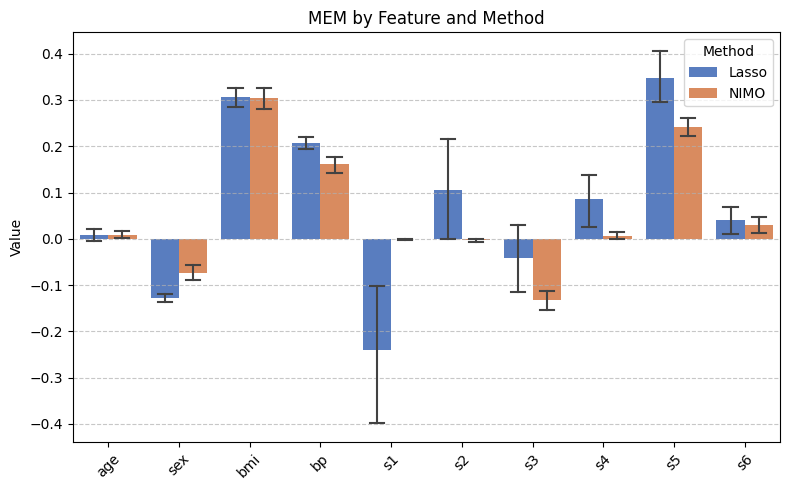

In [14]:
plot_coeffs(lasso_coeffs, nimo_coeffs)


==> Plot MSEs ...
      Lasso        NN       NAM       IMN  LassoNet      NIMO
0  0.509023  0.549341  0.525302  0.638388  0.532128  0.576099
1  0.511218  0.527597  0.535045  0.536245  0.506667  0.536319
2  0.502372  0.501083  0.509562  0.549786  0.494560  0.492780
3  0.470610  0.479079  0.470259  0.561489  0.471795  0.464957
4  0.577265  0.545111  0.566610  0.544395  0.570595  0.569777
5  0.481546  0.488969  0.466760  0.569571  0.474567  0.466484
6  0.453424  0.451146  0.423822  0.529841  0.434457  0.471617
7  0.490602  0.489408  0.467245  0.507162  0.461935  0.444506
8  0.356540  0.436193  0.359711  0.365641  0.345128  0.369871
Mean and Std of MSEs:
Lasso       0.483622
NN          0.496436
NAM         0.480480
IMN         0.533613
LassoNet    0.476870
NIMO        0.488046
dtype: float64
Lasso       0.058961
NN          0.039127
NAM         0.062763
IMN         0.072768
LassoNet    0.063686
NIMO        0.065111
dtype: float64


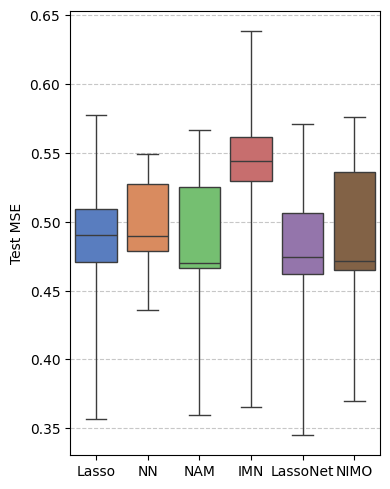

In [12]:
nam_mses = [
    0.5253019318984709,
    0.5350449667658707,
    0.5095618088711318,
    0.47025881950610576,
    0.5666102813818407,
    0.4667601093791699,
    0.42382190024417626,
    0.46724469329023266,
    0.35971112639368785,
]

imn_mses = [
    0.6383884662951291,
    0.5362454837522682,
    0.5497864263273228,
    0.561489013505058,
    0.5443951565506399,
    0.5695710185916428,
    0.5298411011318609,
    0.5071615549385654,
    0.3656410201155797,
]

print("\n==> Plot MSEs ...")
plot_mses(lasso_mses, lassonet_mses, simplenn_mses, nimo_mses, nam_mses, imn_mses)